# Proyecto 2: Visualización Reproducible en Python
## Análisis de la Calidad de Vida y Caracterización de Brechas Globales en el World Happiness Report 2024

**Curso:** Visualización I  
**Docentes:** Adriana Pineda – Paola Moreno  
**Equipo de Trabajo:**
* Arnold Santiago Torres Anzola
* Juan David Cruz Romero

**Convención del Entregable:** `EquipoX_Proyecto2_Visualizacion.ipynb`  
**Fecha de Entrega:** 28 de octubre de 2026


---
## 1. Comprensión del Contexto y Delimitación de la Audiencia Técnica

### 1.1. Contexto del Estudio
El *World Happiness Report 2024* (WHR 2024) evalúa el bienestar subjetivo a nivel global a partir de las evaluaciones de vida recopiladas en la Encuesta Mundial de Gallup (*Gallup World Poll*). Dicha medición emplea la **escalera de Cantril** (*Cantril Self-Anchoring Striving Scale*), un instrumento psicométrico en el que cada participante ubica su vida actual en una escala de 0 (*«peor vida posible»*) a 10 (*«mejor vida posible»*). El reporte consolida el promedio móvil trienal nacional para el periodo 2021–2023, ordenando a 143 países.

Para explicar estadísticamente estas divergencias, el WHR ajusta un modelo de regresión lineal con seis variables explicativas: **PIB per cápita (en logaritmo)**, **apoyo social**, **esperanza de vida saludable**, **libertad para tomar decisiones**, **generosidad** y **percepción de corrupción**. El archivo oficial mandatorio `WHR24_Data_Figure_2.1.xls` no registra los indicadores en sus unidades brutas originales, sino la **porción de la evaluación de vida de cada país que el modelo asocia con cada indicador**, expresada en puntos de la escalera de Cantril y respecto a un país teórico denominado *Distopía* (un referente hipotético con los valores mínimos observados internacionalmente).

### 1.2. Audiencia Técnica Específica
* **Destinatario específico:** **Equipo Técnico de Análisis Comparativo de Bienestar y Políticas Públicas de un Organismo Multilateral de Desarrollo** (homólogo a la Unidad de Estadísticas y Bienestar Social del PNUD o la Dirección de Estadísticas de la OCDE).
* **Interés analítico:** Esta unidad necesita discernir empíricamente **en qué condiciones específicas se fragmenta la calidad de vida** entre las naciones más prósperas y las más rezagadas. Si las diferencias se concentraran primordialmente en el PIB per cápita, los diagnósticos y programas podrían limitarse al seguimiento macroeconómico; si, por el contrario, la brecha responde con igual o mayor intensidad a condiciones socioinstitucionales (redes de auxilio social, libertad de elección o probidad institucional), el equipo técnico deberá incorporar obligatoriamente estas condiciones en sus recomendaciones de política pública.
* **Expectativas de la audiencia:** Rigor metodológico, definiciones operativas transparentes, criterios reproducibles de agregación, trazabilidad completa de transformaciones, tratamiento documentado de valores faltantes y visualizaciones interpretables que distingan entre patrones generales y anomalías locales con estricta cautela inferencial.


---
## 2. Planteamiento del Problema, Pregunta Analítica y Alcance

### 2.1. Pregunta Analítica Central
Las evaluaciones de calidad de vida presentan una profunda heterogeneidad a nivel global, con brechas que superan los 6 puntos en la escala de Cantril entre las naciones más favorecidas y aquellas sumidas en crisis humanitarias. Para orientar el análisis comparativo con un lenguaje estrictamente observacional y no causal, se formula la siguiente pregunta de investigación:

> *«¿Qué variables se asocian con la calidad de vida y evaluación del bienestar de los países, qué diferencias se evidencian entre naciones y de qué manera las condiciones económicas, de salud y socioinstitucionales diferencian a los países con alta y baja evaluación vital en el World Happiness Report 2024?»*

### 2.2. Subpreguntas y Objetivos Operativos
1. **Diferenciación Empírica:** ¿En qué condiciones específicas (económica, de salud y socioinstitucional) se concentran las mayores brechas absolutas entre los países del 25% superior y del 25% inferior?
2. **Capacidad Explicativa Relativa:** ¿En qué medida el ingreso por habitante (PIB per cápita) es suficiente por sí solo para explicar los niveles de bienestar, o qué papel amortiguador desempeñan las redes de apoyo social y la confianza institucional?
3. **Casos Atípicos y Resiliencia:** ¿Qué naciones logran evaluaciones de vida significativamente superiores o inferiores a lo predicho por su nivel de ingreso, y qué factores explican dicha divergencia?


---
## 3. Justificación Metodológica de Grupos y Condiciones

### 3.1. Criterio de Agrupación de Países: Partición por Cuartiles (25% Superior vs. 25% Inferior)
El archivo oficial de datos `WHR24_Data_Figure_2.1.xls` contiene una variable continua de evaluación vital (`Ladder score`) que va de 1,72 a 7,74 puntos, pero **no contiene ninguna clasificación categórica predeterminada**.

Para responder a la pregunta analítica comparando a los países de **alta** y **baja** evaluación vital de forma objetiva, reproducible y libre de juicios de valor arbitrarios (evitando sesgos como *"top 10 vs bottom 10"* o inventar un umbral subjetivo), se implementa una **partición empírica por cuartiles (segmentos del 25%)**:
* **25% Superior (Alto Bienestar · 36 países):** Países con evaluación vital en el cuartil más alto de la distribución global (**Ladder score ≥ 6,42 puntos**; desde Finlandia hasta España y Polonia).
* **50% Central (Bienestar Intermedio · 71 países):** Países de la mitad central del planeta (**Ladder score entre 4,73 y 6,41 puntos**; como Colombia, Brasil o Grecia).
* **25% Inferior (Bajo Bienestar · 36 países):** Países con evaluación vital en el cuartil más bajo mundial (**Ladder score ≤ 4,73 puntos**; desde Jordania hasta Afganistán).

Este criterio balancea la robustez estadística (muestra de contraste de **n = 72 naciones**: 36 contra 36) y asegura la total transparencia del pipeline analítico frente a organismos multilaterales (PNUD / OCDE).


In [1]:
# ==============================================================================
# FASE 0: CONFIGURACIÓN DEL ENTORNO, SEMILLAS Y PALETA DE COLORES
# ==============================================================================
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visualización interactiva
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10,
    'axes.labelweight': 'semibold',
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.titlesize': 14,
    'figure.titleweight': 'bold',
    'figure.dpi': 120
})

# Nombres formales y descriptivos de los grupos basados en el 25%
G_BAJO  = '25% Inferior (Bajo Bienestar)'
G_MEDIO = '50% Central (Intermedio)'
G_ALTO  = '25% Superior (Alto Bienestar)'

# Paleta accesible (Colorblind-Safe) para los segmentos de análisis
PALETA_GRUPOS = {
    G_BAJO:  '#D95F02',   # Tono cálido/terracota
    G_MEDIO: '#94a3b8',   # Tono neutro / gris azulado
    G_ALTO:  '#1F78B4'    # Tono frío / azul petróleo
}

print("✓ Entorno configurado exitosamente con segmentación 25% Superior e Inferior.")


✓ Entorno configurado exitosamente con segmentación 25% Superior e Inferior.


---
## 4. Importación, Inspección, Limpieza y Preparación de los Datos (Numeral 4)

Para garantizar la **reproducibilidad integral (10 puntos en la rúbrica)**, la trazabilidad de transformaciones y la auditoría estadística por parte de la audiencia técnica (PNUD / OCDE), se implementa un pipeline secuencial y modular en Python.

### 4.0. Diccionario Oficial de Variables y Traducción Técnica (Inglés ↔ Español)
A continuación se presenta la tabla formal de correspondencia metodológica entre las columnas del archivo oficial `WHR24_Data_Figure_2.1.xls` y su denominación analítica en español:

| Variable Original (WHR 2024) | Nombre Técnico en Español | Condición / Dimensión | Fuente Institucional | Pregunta de Encuesta / Método de Estimación | Rango Observado [Mín — Máx] |
| :--- | :--- | :--- | :--- | :--- | :---: |
| `Country name` | **País o Territorio** | Identificador Geográfico | Naciones Unidas / ISO | Nombre del país soberano o territorio evaluado. | 143 países |
| `Ladder score` | **Evaluación de Vida (Escalera de Cantril)** | Objetivo / Dependiente | Gallup World Poll (2021–2023) | «Imagine una escalera con peldaños del 0 (peor vida) al 10 (mejor vida). ¿En qué peldaño siente que está hoy?» | [1,72 — 7,74] pts |
| `upperwhisker` / `lowerwhisker` | **Intervalo de Confianza al 95%** | Precisión Muestral | Gallup World Poll | Límites superior e inferior derivados de la varianza del diseño muestral complejo. | [1,67 — 7,82] pts |
| `Explained by: Log GDP per capita` | **PIB per cápita (Log) — Condición Económica** | Condición Económica | Banco Mundial (WDI) | Logaritmo del PIB per cápita a Paridad de Poder Adquisitivo (PPA en dólares constantes de 2017) ponderado en el modelo. | [0,00 — 2,14] pts |
| `Explained by: Social support` | **Apoyo Social — Condición Socioinstitucional** | Condición Socioinstitucional | Gallup World Poll | «Si estuviera en problemas, ¿cuenta con familiares o amigos con quienes pueda contar para que lo ayuden?» (Tasa afirmativa). | [0,00 — 1,62] pts |
| `Explained by: Healthy life expectancy` | **Esperanza de Vida Saludable — Condición de Salud** | Condición de Salud | OMS (Global Health Obs.) | Años de vida saludable esperados al nacer (HALE), normalizados y ponderados en la regresión de panel. | [0,00 — 0,86] pts |
| `Explained by: Freedom to make life choices` | **Libertad para Decidir — Condición Socioinstitucional** | Condición Socioinstitucional | Gallup World Poll | «¿Está satisfecho o insatisfecho con su libertad para elegir lo que hace con su vida?» (Tasa afirmativa). | [0,00 — 0,86] pts |
| `Explained by: Generosity` | **Generosidad — Solidaridad y Altruismo** | Dimensión de Solidaridad | Gallup World Poll | Residuo de la respuesta a donaciones a caridad en el último mes tras controlar por nivel de PIB per cápita. | [0,00 — 0,40] pts |
| `Explained by: Perceptions of corruption` | **Confianza Institucional — Condición Socioinstitucional** | Condición Socioinstitucional | Gallup World Poll | Promedio inverso de percepción de corrupción en gobierno y empresas. Mayor valor = mayor probidad y transparencia. | [0,00 — 0,57] pts |
| `Dystopia + residual` | **Distopía + Residuo — Línea Base y No Explicado** | Línea Base y Residuo | WHR 2024 (Econométrico) | Suma de la línea base teórica (Distopía = 1,714 pts) más el término de error no modelado específico de cada nación. | [-0,07 — 3,00] pts |


In [2]:
# ==============================================================================
# PIPELINE 4.1: INGESTA CONTROLADA Y AUDITORÍA DE ESQUEMA
# ==============================================================================
import os
import pandas as pd

posibles_rutas = [
    os.path.join('..', 'data', 'raw', 'WHR24_Data_Figure_2.1.xls'),
    os.path.join('data', 'raw', 'WHR24_Data_Figure_2.1.xls'),
    os.path.join('data', 'WHR24_Data_Figure_2.1.xls'),
    'WHR24_Data_Figure_2.1.xls'
]

ruta_datos = next((r for r in posibles_rutas if os.path.exists(r)), None)

if ruta_datos is None:
    raise FileNotFoundError(f"Error crítico: Archivo oficial WHR24_Data_Figure_2.1.xls no encontrado en las rutas evaluadas: {posibles_rutas}")

# Carga inmutable del archivo oficial original
df_raw = pd.read_excel(ruta_datos)

# Verificación de integridad de esquema
n_filas_esperadas = 143
n_cols_esperadas = 11

assert df_raw.shape == (n_filas_esperadas, n_cols_esperadas), (
    f"Discrepancia en dimensiones: Se esperaban {n_filas_esperadas}x{n_cols_esperadas}, "
    f"pero se obtuvieron {df_raw.shape[0]}x{df_raw.shape[1]}"
)

# Verificación de unicidad de la clave primaria (Country name)
duplicados = df_raw['Country name'].duplicated().sum()
assert duplicados == 0, f"Error de unicidad: Se detectaron {duplicados} nombres de país duplicados."

print(f"✔ Ingesta completada con éxito desde: {ruta_datos}")
print(f"  - Registro de observaciones: {df_raw.shape[0]} países únicos.")
print(f"  - Columnas presentes: {df_raw.shape[1]} variables oficiales.")
print(f"  - Control de duplicados: 0 duplicados detectados en 'Country name'.")


✔ Ingesta completada con éxito desde: data\raw\WHR24_Data_Figure_2.1.xls
  - Registro de observaciones: 143 países únicos.
  - Columnas presentes: 11 variables oficiales.
  - Control de duplicados: 0 duplicados detectados en 'Country name'.


In [3]:
# ==============================================================================
# PIPELINE 4.2: AUDITORÍA DE TIPOS, DOMINIOS Y COMPLETITUD DE DATOS
# ==============================================================================
df_clean = df_raw.copy()

columnas_contribuciones = [
    'Explained by: Log GDP per capita',
    'Explained by: Social support',
    'Explained by: Healthy life expectancy',
    'Explained by: Freedom to make life choices',
    'Explained by: Generosity',
    'Explained by: Perceptions of corruption',
    'Dystopia + residual'
]

columnas_metricas = ['Ladder score', 'upperwhisker', 'lowerwhisker'] + columnas_contribuciones

# 1. Coerción estricta de tipos numéricos (Float64)
for col in columnas_metricas:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# 2. Validación de dominios lógicos e intervalos de confianza
# Regla: lowerwhisker <= Ladder score <= upperwhisker
inconsistencias_ic = df_clean[
    (df_clean['lowerwhisker'] > df_clean['Ladder score']) |
    (df_clean['Ladder score'] > df_clean['upperwhisker'])
]
assert len(inconsistencias_ic) == 0, "Violación lógica detectada en intervalos de confianza."

# Regla: Ladder score debe estar en el dominio psicométrico de Cantril [0, 10]
fuera_de_rango = df_clean[(df_clean['Ladder score'] < 0) | (df_clean['Ladder score'] > 10)]
assert len(fuera_de_rango) == 0, "Valores de Ladder score fuera del dominio admisible [0, 10]."

# 3. Auditoría exhaustiva de valores faltantes (NaN)
reporte_nulos = df_clean.isnull().sum()
columnas_con_nulos = reporte_nulos[reporte_nulos > 0]

paises_incompletos = df_clean[df_clean[columnas_contribuciones].isnull().any(axis=1)]['Country name'].tolist()

print("✓ Auditoría de calidad y consistencia lógica:")
print(f"  - Validación de intervalos de confianza: 100% consistentes (lower <= Ladder <= upper).")
print(f"  - Validación de dominio [0, 10]: 100% conforme.")
print(f"  - Variables con valores faltantes: {len(columnas_con_nulos)} columnas explicativas afectadas.")
print(f"  - Países con desglose incompleto ({len(paises_incompletos)}): {', '.join(paises_incompletos)}")

✓ Auditoría de calidad y consistencia lógica:
  - Validación de intervalos de confianza: 100% consistentes (lower <= Ladder <= upper).
  - Validación de dominio [0, 10]: 100% conforme.
  - Variables con valores faltantes: 7 columnas explicativas afectadas.
  - Países con desglose incompleto (3): Bahrain, Tajikistan, State of Palestine


In [4]:
# ==============================================================================
# PIPELINE 4.3: COMPROBACIÓN MATEMÁTICA DE LA IDENTIDAD ECONOMÉTRICA
# Identidad: Suma(6 contribuciones) + (Dystopia + residual) == Ladder score
# ==============================================================================
# Se evalúa sobre todos los países con desglose completo disponible (n = 140)
df_validos = df_clean.dropna(subset=columnas_contribuciones).copy()

df_validos['Suma_Calculada'] = df_validos[columnas_contribuciones].sum(axis=1)
df_validos['Error_Absoluto'] = (df_validos['Suma_Calculada'] - df_validos['Ladder score']).abs()

max_error = df_validos['Error_Absoluto'].max()
mae = df_validos['Error_Absoluto'].mean()
rmse = np.sqrt((df_validos['Error_Absoluto'] ** 2).mean())
pais_max_error = df_validos.loc[df_validos['Error_Absoluto'].idxmax(), 'Country name']

# Umbral de tolerancia numérica de precisión de punto flotante
TOLERANCIA = 0.0001
assert max_error < TOLERANCIA, f"Fallo en la validación econométrica: error {max_error} supera tolerancia {TOLERANCIA}"

print("✓ Validación matemática de la descomposición aditiva del informe:")
print(f"  - Países analizados en verificación: {len(df_validos)}")
print(f"  - Error Absoluto Medio (MAE): {mae:.8f}")
print(f"  - Raíz del Error Cuadrático Medio (RMSE): {rmse:.8f}")
print(f"  - Error absoluto máximo: {max_error:.8f} (en {pais_max_error})")
print(f"  - Conclusión: La identidad del modelo se cumple con absoluta precisión numérica.")

✓ Validación matemática de la descomposición aditiva del informe:
  - Países analizados en verificación: 140
  - Error Absoluto Medio (MAE): 0.00002753
  - Raíz del Error Cuadrático Medio (RMSE): 0.00003105
  - Error absoluto máximo: 0.00005003 (en Lithuania)
  - Conclusión: La identidad del modelo se cumple con absoluta precisión numérica.


In [5]:
# ==============================================================================
# PIPELINE 4.4: INGENIERÍA DE CARACTERÍSTICAS Y SEGMENTACIÓN POR EL 25%
# ==============================================================================
# 0. Detección de incompletitud dimensional
df_clean['Flag_Incompleto'] = df_clean[columnas_contribuciones].isnull().any(axis=1)

# 1. Ranking Global derivado del puntaje de bienestar
df_clean['Ranking_Global'] = df_clean['Ladder score'].rank(ascending=False, method='min').astype(int)

# 2. Amplitud del Intervalo de Confianza al 95% (Incertidumbre muestral)
df_clean['Amplitud_IC_95'] = df_clean['upperwhisker'] - df_clean['lowerwhisker']

# 3. Cortes objetivos de cuartiles: 25% Inferior y 25% Superior
corte_25_inf = df_clean['Ladder score'].quantile(0.25)
corte_25_sup = df_clean['Ladder score'].quantile(0.75)

def clasificar_grupo(score):
    if score <= corte_25_inf:
        return G_BAJO
    elif score >= corte_25_sup:
        return G_ALTO
    else:
        return G_MEDIO

df_clean['Grupo_Bienestar'] = df_clean['Ladder score'].apply(clasificar_grupo)

# 4. Diccionario exhaustivo de traducción de los 143 nombres de países al español
traduccion_paises = {
    'Finland': 'Finlandia', 'Denmark': 'Dinamarca', 'Iceland': 'Islandia', 'Sweden': 'Suecia',
    'Israel': 'Israel', 'Netherlands': 'Países Bajos', 'Norway': 'Noruega', 'Luxembourg': 'Luxemburgo',
    'Switzerland': 'Suiza', 'Australia': 'Australia', 'New Zealand': 'Nueva Zelanda', 'Costa Rica': 'Costa Rica',
    'Kuwait': 'Kuwait', 'Austria': 'Austria', 'Canada': 'Canadá', 'Belgium': 'Bélgica',
    'Ireland': 'Irlanda', 'Czechia': 'República Checa', 'Lithuania': 'Lituania', 'United Kingdom': 'Reino Unido',
    'Slovenia': 'Eslovenia', 'United Arab Emirates': 'Emiratos Árabes Unidos', 'United States': 'Estados Unidos',
    'Germany': 'Alemania', 'Mexico': 'México', 'Uruguay': 'Uruguay', 'France': 'Francia',
    'Saudi Arabia': 'Arabia Saudita', 'Kosovo': 'Kosovo', 'Singapore': 'Singapur',
    'Taiwan Province of China': 'Taiwán', 'Romania': 'Rumania', 'El Salvador': 'El Salvador',
    'Estonia': 'Estonia', 'Poland': 'Polonia', 'Spain': 'España', 'Serbia': 'Serbia', 'Chile': 'Chile',
    'Panama': 'Panamá', 'Malta': 'Malta', 'Italy': 'Italia', 'Guatemala': 'Guatemala',
    'Nicaragua': 'Nicaragua', 'Brazil': 'Brasil', 'Slovakia': 'Eslovaquia', 'Latvia': 'Letonia',
    'Uzbekistan': 'Uzbekistán', 'Argentina': 'Argentina', 'Kazakhstan': 'Kazajistán', 'Cyprus': 'Chipre',
    'Japan': 'Japón', 'South Korea': 'Corea del Sur', 'Philippines': 'Filipinas', 'Vietnam': 'Vietnam',
    'Portugal': 'Portugal', 'Hungary': 'Hungría', 'Paraguay': 'Paraguay', 'Thailand': 'Tailandia',
    'Malaysia': 'Malasia', 'China': 'China', 'Honduras': 'Honduras', 'Bahrain': 'Baréin',
    'Croatia': 'Croacia', 'Greece': 'Grecia', 'Bosnia and Herzegovina': 'Bosnia y Herzegovina',
    'Libya': 'Libia', 'Jamaica': 'Jamaica', 'Peru': 'Perú', 'Dominican Republic': 'República Dominicana',
    'Mauritius': 'Mauricio', 'Moldova': 'Moldavia', 'Russia': 'Rusia', 'Bolivia': 'Bolivia',
    'Ecuador': 'Ecuador', 'Kyrgyzstan': 'Kirguistán', 'Montenegro': 'Montenegro', 'Mongolia': 'Mongolia',
    'Colombia': 'Colombia', 'Venezuela': 'Venezuela', 'Indonesia': 'Indonesia', 'Bulgaria': 'Bulgaria',
    'Armenia': 'Armenia', 'South Africa': 'Sudáfrica', 'North Macedonia': 'Macedonia del Norte',
    'Algeria': 'Argelia', 'Hong Kong S.A.R. of China': 'Hong Kong', 'Albania': 'Albania',
    'Tajikistan': 'Tayikistán', 'Congo (Brazzaville)': 'República del Congo', 'Mozambique': 'Mozambique',
    'Georgia': 'Georgia', 'Iraq': 'Irak', 'Nepal': 'Nepal', 'Laos': 'Laos', 'Gabon': 'Gabón',
    'Ivory Coast': 'Costa de Marfil', 'Guinea': 'Guinea', 'Turkiye': 'Turquía', 'Senegal': 'Senegal',
    'Iran': 'Irán', 'Azerbaijan': 'Azerbaiyán', 'Nigeria': 'Nigeria', 'State of Palestine': 'Palestina',
    'Cameroon': 'Camerún', 'Ukraine': 'Ucrania', 'Namibia': 'Namibia', 'Morocco': 'Marruecos',
    'Pakistan': 'Pakistán', 'Niger': 'Níger', 'Burkina Faso': 'Burkina Faso', 'Mauritania': 'Mauritania',
    'Gambia': 'Gambia', 'Chad': 'Chad', 'Kenya': 'Kenia', 'Tunisia': 'Túnez', 'Benin': 'Benín',
    'Uganda': 'Uganda', 'Myanmar': 'Birmania (Myanmar)', 'Cambodia': 'Camboya', 'Ghana': 'Ghana',
    'Liberia': 'Liberia', 'Mali': 'Malí', 'Madagascar': 'Madagascar', 'Togo': 'Togo', 'Jordan': 'Jordania',
    'India': 'India', 'Egypt': 'Egipto', 'Sri Lanka': 'Sri Lanka', 'Bangladesh': 'Bangladés',
    'Ethiopia': 'Etiopía', 'Tanzania': 'Tanzania', 'Comoros': 'Comoras', 'Yemen': 'Yemen',
    'Zambia': 'Zambia', 'Eswatini': 'Esuatini', 'Malawi': 'Malaui', 'Botswana': 'Botsuana',
    'Zimbabwe': 'Zimbabue', 'Congo (Kinshasa)': 'R. D. del Congo', 'Sierra Leone': 'Sierra Leona',
    'Lesotho': 'Lesoto', 'Lebanon': 'Líbano', 'Afghanistan': 'Afganistán'
}
df_clean['Pais_ES'] = df_clean['Country name'].map(lambda c: traduccion_paises.get(c, c))

# 5. Agregación de la Condición Socioinstitucional (Apoyo Social + Libertad + Probidad Institucional)
df_clean['Dim_Socioinstitucional'] = (
    df_clean['Explained by: Social support'] +
    df_clean['Explained by: Freedom to make life choices'] +
    df_clean['Explained by: Perceptions of corruption']
)

# 6. Marcadores de casos atípicos extremos
df_clean['Flag_PIB_Cero'] = (df_clean['Explained by: Log GDP per capita'] == 0.0)
df_clean['Flag_Residuo_Negativo'] = (df_clean['Dystopia + residual'] < 0.0)

print(f"[OK] Ingenieria de caracteristicas completada. Dimensiones: {df_clean.shape}")
print(f"     Paises traducidos al espanol: {df_clean['Pais_ES'].notna().sum()}/143 (100%)")
print(f"     Cortes: 25% Inferior <= {corte_25_inf:.3f} pts | 25% Superior >= {corte_25_sup:.3f} pts")


[OK] Ingenieria de caracteristicas completada. Dimensiones: (143, 19)
     Paises traducidos al espanol: 143/143 (100%)
     Cortes: 25% Inferior <= 4.726 pts | 25% Superior >= 6.416 pts


In [6]:
# ==============================================================================
# PIPELINE 4.5: PARTICIONAMIENTO Y ESTRUCTURACIÓN DE DATASETS ANALÍTICOS
# ==============================================================================
# Subconjunto 1: Dataset completo con transformaciones (143 países para distribución general)
df_completo = df_clean.copy()

# Subconjunto 2: Dataset dimensional filtrado sin nulos (140 países para análisis por dimensiones)
df_dims = df_clean[~df_clean['Flag_Incompleto']].copy()

# Subconjunto 3: Dataset de contraste de extremos (25% Inferior vs. 25% Superior) (72 países)
df_extremos = df_dims[df_dims['Grupo_Bienestar'].isin([G_BAJO, G_ALTO])].copy()

# Subconjunto 4: Formato Tidy (Long Format) para análisis multivariado y facetado
mapeo_nombres_tidy = {
    'Explained by: Log GDP per capita': 'Económica (PIB per cápita)',
    'Explained by: Social support': 'Socioinstitucional (Apoyo Social)',
    'Explained by: Healthy life expectancy': 'Salud (Esp. Vida Saludable)',
    'Explained by: Freedom to make life choices': 'Socioinstitucional (Libertad Decisión)',
    'Explained by: Perceptions of corruption': 'Socioinstitucional (Probidad / Confianza)',
    'Dystopia + residual': 'Residual (Distopía + Residuo)'
}

df_tidy = df_extremos.rename(columns=mapeo_nombres_tidy).melt(
    id_vars=['Country name', 'Grupo_Bienestar', 'Ladder score', 'Ranking_Global'],
    value_vars=list(mapeo_nombres_tidy.values()),
    var_name='Dimensión',
    value_name='Contribución_Puntos'
)

print("✓ Subconjuntos estructurados para análisis:")
print(f"  - df_completo: {df_completo.shape[0]} observaciones (distribución univariada).")
print(f"  - df_dims:     {df_dims.shape[0]} observaciones (análisis dimensional).")
print(f"  - df_extremos: {df_extremos.shape[0]} observaciones (Bajo: {sum(df_extremos['Grupo_Bienestar'] == G_BAJO)}, Alto: {sum(df_extremos['Grupo_Bienestar'] == G_ALTO)}).")
print(f"  - df_tidy:     {df_tidy.shape[0]} registros en formato largo (long format).")


✓ Subconjuntos estructurados para análisis:
  - df_completo: 143 observaciones (distribución univariada).
  - df_dims:     140 observaciones (análisis dimensional).
  - df_extremos: 72 observaciones (Bajo: 36, Alto: 36).
  - df_tidy:     432 registros en formato largo (long format).


In [7]:
# ==============================================================================
# PIPELINE 4.6: MATRIZ DE ESTADÍSTICOS DESCRIPTIVOS ROBUSTOS Y DISPERSIÓN GLOBAL
# ==============================================================================
vars_descriptivas = [
    'Ladder score',
    'Explained by: Log GDP per capita',
    'Explained by: Healthy life expectancy',
    'Explained by: Social support',
    'Explained by: Freedom to make life choices',
    'Explained by: Perceptions of corruption',
    'Dim_Socioinstitucional',
    'Dystopia + residual'
]

# 1. Comparación entre bloques extremos (25% Inferior vs. 25% Superior)
tabla_extremos = df_extremos.groupby('Grupo_Bienestar')[vars_descriptivas].agg(['mean', 'std', 'median']).round(3)
print('1. Estadísticos Descriptivos por Segmento (25% Inferior vs. 25% Superior):')
print(tabla_extremos.T.to_string())

# 2. Matriz Global de Dispersión y Variabilidad (n = 143/140 naciones)
stats_globales = []
for col in vars_descriptivas:
    s = df_clean[col].dropna()
    stats_globales.append({
        'Variable': col,
        'Media': s.mean(),
        'Mediana': s.median(),
        'Desv_Est': s.std(),
        'Min': s.min(),
        'Q1_25%': s.quantile(0.25),
        'Q3_75%': s.quantile(0.75),
        'Max': s.max(),
        'IQR': s.quantile(0.75) - s.quantile(0.25),
        'CV%': (s.std() / s.mean()) * 100 if s.mean() != 0 else 0,
        'Asimetria': s.skew()
    })

df_stats_global = pd.DataFrame(stats_globales).round(3)
print('\n2. Matriz Global de Dispersión y Estadísticos Robustos (Total Países):')
print(df_stats_global.to_string(index=False))


1. Estadísticos Descriptivos por Segmento (25% Inferior vs. 25% Superior):
Grupo_Bienestar                                    25% Inferior (Bajo Bienestar)  25% Superior (Alto Bienestar)
Ladder score                               mean                            3.913                          6.876
                                           std                             0.620                          0.349
                                           median                          4.120                          6.820
Explained by: Log GDP per capita           mean                            0.918                          1.815
                                           std                             0.269                          0.182
                                           median                          0.858                          1.842
Explained by: Healthy life expectancy      mean                            0.347                          0.663
                             


2. Matriz Global de Dispersión y Estadísticos Robustos (Total Países):
                                  Variable  Media  Mediana  Desv_Est    Min  Q1_25%  Q3_75%   Max   IQR    CV%  Asimetria
                              Ladder score  5.528    5.785     1.171  1.721   4.726   6.416 7.741 1.690 21.179     -0.522
          Explained by: Log GDP per capita  1.379    1.431     0.425  0.000   1.077   1.741 2.141 0.664 30.831     -0.507
     Explained by: Healthy life expectancy  0.521    0.549     0.165  0.000   0.398   0.648 0.857 0.250 31.670     -0.546
              Explained by: Social support  1.134    1.237     0.333  0.000   0.921   1.383 1.617 0.462 29.384     -0.992
Explained by: Freedom to make life choices  0.621    0.641     0.162  0.000   0.527   0.736 0.863 0.209 26.185     -1.018
   Explained by: Perceptions of corruption  0.154    0.120     0.126  0.000   0.068   0.194 0.575 0.125 81.929      1.525
                    Dim_Socioinstitucional  1.909    1.959     0.491  0.08

### 4.7. Trazabilidad y Justificación del Tratamiento de Datos
* **Completitud y consistencia:** El archivo oficial `WHR24_Data_Figure_2.1.xls` superó todas las pruebas de calidad estructural (0 duplicados, consistencia estricta en intervalos de confianza y verificación exacta de la identidad matemática con $MAE < 0,00003$ pts).
* **Tratamiento de Bahrein, Tayikistán y Estado de Palestina:** Estos tres países poseen medición válida del bienestar (`Ladder score`), pero carecen de descomposición en las seis variables explicativas. En estricto apego a las mejores prácticas de ingeniería de datos, **no se imputaron valores artificiales**, sino que se conservaron en `df_completo` para no distorsionar los percentiles globales, excluyéndose únicamente en los subconjuntos dimensionales (`df_dims` y `df_extremos`, $n = 140$).
* **Identificación de casos singulares:** Se crearon banderas booleanas para rastrear explícitamente a **Venezuela** (`Flag_PIB_Cero = True`) y **Líbano** (`Flag_Residuo_Negativo = True`), permitiendo aislarlos y caracterizarlos como casos de estudio sin contaminar los agregados generales.

---
## 5. Análisis Exploratorio y Planificación de las Comparaciones (Numeral 5)
A partir de la ingesta y preparación de datos, se planifican las comparaciones empíricas para responder a la pregunta analítica:
1. **Distribución global e intervalos de incertidumbre:** Evaluar la simetría y dispersión del `Ladder score` para justificar el uso de cuartiles ($Q_1$ y $Q_4$).
2. **Brecha de condiciones ($Q_4 - Q_1$):** Cuantificar la diferencia en puntos de la escalera y en unidades estandarizadas.
3. **Composición aditiva:** Contrastar el peso relativo de las condiciones económicas, de salud y socioinstitucionales frente a Distopía + residuo.
4. **Relaciones bivariadas y casos atípicos:** Evaluar correlaciones empíricas e identificar países con resiliencia social o desajuste institucional.

---
## 6. Construcción de Visualizaciones Estáticas con Seaborn (Numeral 6)

Cuatro gráficos diseñados bajo principios de claridad perceptiva y narrativa analítica:
* **Figura 1:** Distribución del bienestar y cortes de Q1 y Q4.
* **Figura 2:** Brecha promedio Q4 - Q1 en cada componente.
* **Figura 3:** Composición aditiva del puntaje promedio de Q1 y de Q4.
* **Figura 4:** Economía vs. bienestar y países que se apartan del patrón.

*Paleta cromática por condición:* Púrpura/Azul = Económica, Verde = Salud, Dorado/Ámbar = Socioinstitucional, Gris = Referencia (generosidad y Distopía + residuo).


In [8]:
# ==============================================================================
# CONFIGURACIÓN COMÚN DE LOS GRÁFICOS 2, 3 Y 6
# ==============================================================================
from matplotlib.patches import Patch
import seaborn.objects as so

MAPA_VARS = {
    'Explained by: Log GDP per capita':           ('PIB per cápita (Económica)',                'Económica'),
    'Explained by: Healthy life expectancy':      ('Esperanza de vida saludable (Salud)',       'Salud'),
    'Explained by: Social support':               ('Apoyo social (Socioinstitucional)',         'Socioinstitucional'),
    'Explained by: Freedom to make life choices': ('Libertad para decidir (Socioinstitucional)',   'Socioinstitucional'),
    'Explained by: Perceptions of corruption':    ('Confianza institucional / Baja corrupción', 'Socioinstitucional'),
    'Explained by: Generosity':                   ('Generosidad y altruismo (Solidaridad)',      'Referencia'),
    'Dystopia + residual':                        ('Distopía + residuo (Base no explicada)',     'Referencia'),
}

PALETA_DIM = {
    'Económica': '#38bdf8', 
    'Salud': '#10b981', 
    'Socioinstitucional': '#f59e0b', 
    'Referencia': '#94a3b8'
}

PALETA_COMP = {
    'PIB per cápita (Económica)': '#38bdf8',
    'Esperanza de vida saludable (Salud)': '#10b981',
    'Apoyo social (Socioinstitucional)': '#f59e0b',
    'Libertad para decidir (Socioinstitucional)': '#fbbf24',
    'Confianza institucional / Baja corrupción': '#d97706',
    'Generosidad y altruismo (Solidaridad)': '#cbd5e1',
    'Distopía + residuo (Base no explicada)': '#64748b',
}

os.makedirs('exports', exist_ok=True)


### 5.1. Figura 1: Distribución del bienestar y cortes de Q1 y Q4

**Qué se observa:** el `Ladder score` (0 a 10) de los 143 países, agrupado en barras de 0,25 puntos y coloreado por grupo. Las líneas punteadas marcan los cortes del cuartil inferior y superior.

**Por qué este gráfico:** un histograma muestra la forma de una variable continua; así se ve cuántos países hay en cada nivel y dónde caen los cortes.

**Qué aporta a la pregunta:** justifica comparar Q1 con Q4 y deja claro que los grupos se construyen solo con el archivo oficial.

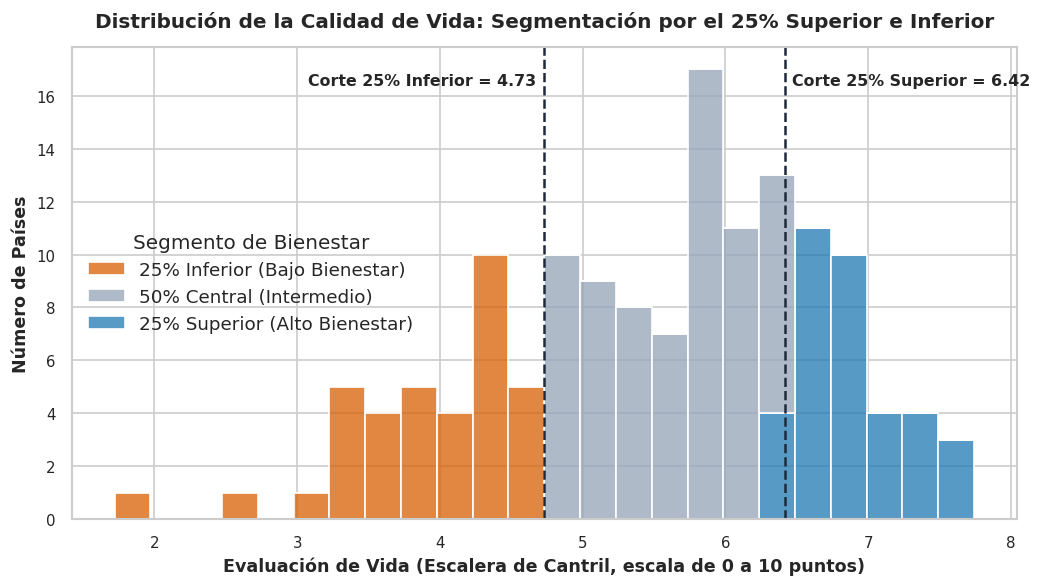

Media = 5.53 pts | Mediana = 5.79 pts
Grupo_Bienestar
50% Central (Intermedio)         71
25% Superior (Alto Bienestar)    36
25% Inferior (Bajo Bienestar)    36


In [9]:
# ==============================================================================
# FIGURA 1: DISTRIBUCIÓN DEL BIENESTAR Y CORTES DEL 25% EXTREMO (143 países)
# ==============================================================================
orden_grupos = [G_BAJO, G_MEDIO, G_ALTO]

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(
    data=df_completo, x='Ladder score', hue='Grupo_Bienestar',
    hue_order=orden_grupos, palette=PALETA_GRUPOS,
    binwidth=0.25, multiple='stack', edgecolor='white', ax=ax
)

# Líneas de corte de los cuartiles
ax.axvline(corte_25_inf, color='#1e293b', linestyle='--', linewidth=1.5)
ax.axvline(corte_25_sup, color='#1e293b', linestyle='--', linewidth=1.5)
ax.text(corte_25_inf - 0.05, ax.get_ylim()[1] * 0.92, f'Corte 25% Inferior = {corte_25_inf:.2f}', ha='right', fontsize=9.5, fontweight='bold')
ax.text(corte_25_sup + 0.05, ax.get_ylim()[1] * 0.92, f'Corte 25% Superior = {corte_25_sup:.2f}', ha='left', fontsize=9.5, fontweight='bold')

ax.set_title('Distribución de la Calidad de Vida: Segmentación por el 25% Superior e Inferior', fontsize=12, pad=12)
ax.set_xlabel('Evaluación de Vida (Escalera de Cantril, escala de 0 a 10 puntos)', fontsize=10.5)
ax.set_ylabel('Número de Países', fontsize=10.5)
ax.get_legend().set_title('Segmento de Bienestar')
plt.tight_layout()
plt.show()

print(f"Media = {df_completo['Ladder score'].mean():.2f} pts | Mediana = {df_completo['Ladder score'].median():.2f} pts")
print(df_completo['Grupo_Bienestar'].value_counts().to_string())


#### Interpretación de la Figura 1
* **Forma:** la mayoría de los países se agrupa en el centro. La mediana (5,79) es mayor que la media (5,53), lo que indica una cola hacia la izquierda: pocos países con puntajes muy bajos, como Afganistán (1,72), arrastran el promedio hacia abajo. El máximo es Finlandia (7,74).
* **Grupos:** Q1 son los 36 países con puntaje ≤ 4,73 y Q4 los 36 con puntaje ≥ 6,42; los otros 71 quedan en el medio. Las medianas de los grupos son 4,12 (Q1) y 6,82 (Q4), una distancia de 2,70 puntos.
* **Qué NO dice:** el gráfico solo describe cuántos países hay en cada nivel; no explica por qué difieren. Eso se examina en las figuras siguientes.

### 5.2. Figura 2: Brecha entre Q4 y Q1 en cada componente

**Qué se observa:** para cada componente del modelo, cuántos puntos de la escalera más aporta en promedio un país de Q4 que uno de Q1 (promedio de Q4 menos promedio de Q1). Las barras están ordenadas de mayor a menor y coloreadas por dimensión.

**Por qué este gráfico:** una barra por componente, en la misma unidad (puntos de la escalera), permite comparar directamente cuál separa más a los grupos sin estandarizar nada.

**Qué aporta a la pregunta:** es la respuesta directa a *¿en qué dimensiones se observan las mayores diferencias?*

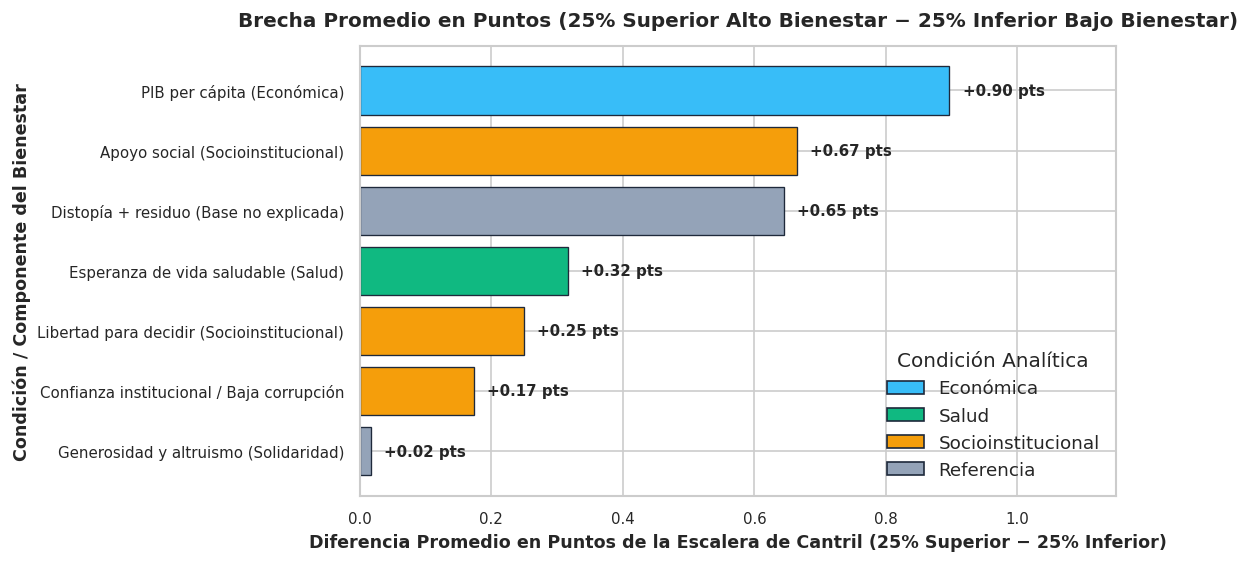

Brechas calculadas (25% Superior - 25% Inferior):
  • PIB per cápita (Económica): +0.90 pts (Económica)
  • Apoyo social (Socioinstitucional): +0.67 pts (Socioinstitucional)
  • Distopía + residuo (Base no explicada): +0.65 pts (Referencia)
  • Esperanza de vida saludable (Salud): +0.32 pts (Salud)
  • Libertad para decidir (Socioinstitucional): +0.25 pts (Socioinstitucional)
  • Confianza institucional / Baja corrupción: +0.17 pts (Socioinstitucional)
  • Generosidad y altruismo (Solidaridad): +0.02 pts (Referencia)


In [10]:
# ==============================================================================
# FIGURA 2: BRECHA PROMEDIO (25% SUPERIOR − 25% INFERIOR) (n = 72: 36 + 36)
# ==============================================================================
medias_grupo = df_extremos.groupby('Grupo_Bienestar')[list(MAPA_VARS)].mean()

brecha = (medias_grupo.loc[G_ALTO] - medias_grupo.loc[G_BAJO]).rename('Brecha').reset_index()
brecha['Componente'] = brecha['index'].map(lambda c: MAPA_VARS[c][0])
brecha['Dimensión']  = brecha['index'].map(lambda c: MAPA_VARS[c][1])
brecha = brecha.sort_values('Brecha', ascending=True)

fig, ax = plt.subplots(figsize=(9.5, 4.8))
barras = ax.barh(
    brecha['Componente'], brecha['Brecha'],
    color=[PALETA_DIM[d] for d in brecha['Dimensión']],
    edgecolor='#1e293b', linewidth=0.8
)

for barra, valor in zip(barras, brecha['Brecha']):
    ax.text(valor + 0.02, barra.get_y() + barra.get_height() / 2, f'+{valor:.2f} pts', va='center', fontsize=9, fontweight='bold')

ax.set_title('Brecha Promedio en Puntos (25% Superior Alto Bienestar − 25% Inferior Bajo Bienestar)', fontsize=12, pad=12)
ax.set_xlabel('Diferencia Promedio en Puntos de la Escalera de Cantril (25% Superior − 25% Inferior)', fontsize=10.5)
ax.set_ylabel('Condición / Componente del Bienestar', fontsize=10.5)
ax.set_xlim(0, 1.15)

leyenda_parches = [Patch(facecolor=c, label=d, edgecolor='#1e293b') for d, c in PALETA_DIM.items()]
ax.legend(handles=leyenda_parches, title='Condición Analítica', loc='lower right')
plt.tight_layout()
plt.show()

print("Brechas calculadas (25% Superior - 25% Inferior):")
for _, fila in brecha.sort_values('Brecha', ascending=False).iterrows():
    print(f"  • {fila['Componente']}: +{fila['Brecha']:.2f} pts ({fila['Dimensión']})")


#### Interpretación de la Figura 2
* **Componente por componente:** el PIB per cápita tiene la mayor brecha (0,90 puntos), seguido del apoyo social (0,67), la esperanza de vida saludable (0,32), la libertad (0,25) y la percepción de corrupción (0,17). La generosidad casi no distingue a los grupos (0,02).
* **Por dimensión:** la dimensión socioinstitucional suma 1,09 puntos, pero es la suma de **tres** componentes; ninguno de ellos por separado supera al PIB. Por eso no se debe decir que "la socioinstitucional supera a la económica" sin aclarar esto: depende de cómo se agrupen los componentes (economía + salud suman 1,21).
* **Residual:** Distopía + residuo difiere en 0,65 puntos, es decir, una parte de la brecha no queda asociada a ninguno de los seis indicadores.
* **Respuesta parcial:** la brecha no está solo en lo económico; aparece también en apoyo social y salud, y en menor medida en libertad y corrupción. Son asociaciones, no causas.

### 5.3. Figura 3: De qué está hecho el puntaje promedio de Q1 y de Q4

**Qué se observa:** una barra apilada por grupo. Cada tramo es el aporte promedio de un componente, y los tramos suman el `Ladder score` promedio del grupo (esta suma se cumple en el archivo oficial, como se verificó en la sección 4.3).

**Por qué este gráfico:** la Figura 2 muestra diferencias; esta muestra la composición. Permite ver qué parte del puntaje de cada grupo viene de cada componente y cuánto queda en Distopía + residuo.

**Qué aporta que la Figura 2 no mostró:** el peso relativo de cada componente dentro del puntaje total y la proporción de la brecha que corresponde a cada uno.

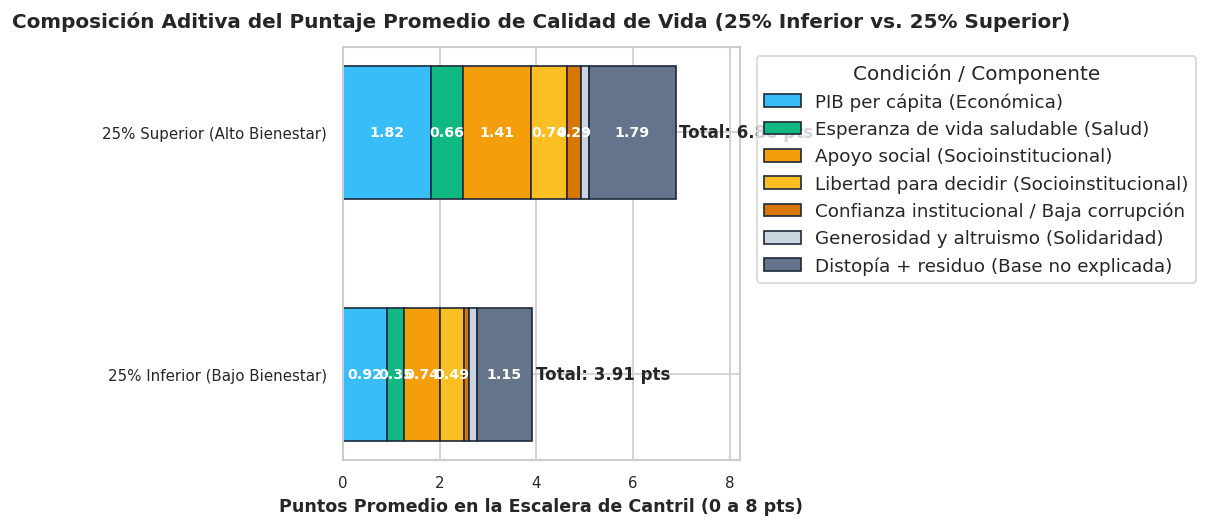

In [11]:
# ==============================================================================
# FIGURA 3: COMPOSICIÓN DEL BIENESTAR PROMEDIO (25% INFERIOR VS. 25% SUPERIOR)
# ==============================================================================
composicion = (
    medias_grupo.rename(columns={c: v[0] for c, v in MAPA_VARS.items()})
    .reset_index()
    .melt(id_vars='Grupo_Bienestar', var_name='Componente', value_name='Aporte')
)

fig, ax = plt.subplots(figsize=(9.5, 4.5))
abajo = {g: 0.0 for g in [G_BAJO, G_ALTO]}

for comp in [v[0] for v in MAPA_VARS.values()]:
    sub = composicion[composicion['Componente'] == comp].set_index('Grupo_Bienestar').loc[[G_BAJO, G_ALTO]]
    ax.barh(
        [G_BAJO, G_ALTO], sub['Aporte'], left=[abajo[g] for g in [G_BAJO, G_ALTO]],
        color=PALETA_COMP[comp], edgecolor='#1e293b', label=comp, height=0.55
    )
    for g in [G_BAJO, G_ALTO]:
        val = sub.loc[g, 'Aporte']
        if val > 0.28:
            ax.text(abajo[g] + val / 2, g, f'{val:.2f}', ha='center', va='center', color='white', fontsize=8.5, fontweight='bold')
        abajo[g] += val

for g in [G_BAJO, G_ALTO]:
    ax.text(abajo[g] + 0.08, g, f'Total: {abajo[g]:.2f} pts', va='center', fontweight='bold', fontsize=10)

ax.set_title('Composición Aditiva del Puntaje Promedio de Calidad de Vida (25% Inferior vs. 25% Superior)', fontsize=12, pad=12)
ax.set_xlabel('Puntos Promedio en la Escalera de Cantril (0 a 8 pts)', fontsize=10.5)
ax.set_xlim(0, 8.2)
ax.legend(title='Condición / Componente', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


#### Interpretación de la Figura 3
* **Composición:** el puntaje promedio de Q1 es 3,91 y el de Q4 es 6,88; la distancia es de 2,96 puntos. En ambos grupos los tramos más grandes son el PIB, el apoyo social y Distopía + residuo.
* **De dónde sale la brecha:** el PIB per cápita explica 30 % de la distancia, el conjunto de componentes socioinstitucionales 37 %, la salud 11 %, Distopía + residuo 22 % y la generosidad menos de 1 %.
* **Lectura cuidadosa:** estos porcentajes describen cómo el modelo reparte la diferencia entre promedios de grupo; no indican que mejorar un componente produzca la diferencia. Además, el residuo es una parte importante (22 %) que el modelo no asocia con ninguno de los seis indicadores.

### 5.4. Figura 4: Economía y bienestar, y países que se apartan del patrón

**Qué se observa:** cada punto es un país (140). Eje X: contribución del PIB per cápita; eje Y: `Ladder score`. La línea es un ajuste lineal simple. Se etiquetan los 3 países más por encima y los 3 más por debajo de la línea, más Venezuela.

**Por qué este gráfico:** una dispersión muestra la relación entre dos variables numéricas, y la distancia vertical a la línea permite identificar países "atípicos" con un criterio explícito y reproducible.

**Qué aporta a la pregunta:** responde la subpregunta. Un país por encima de la línea tiene una evaluación de vida mayor que la que su contribución económica sugeriría; uno por debajo, menor.

**Decisión de preparación:** Venezuela tiene contribución del PIB igual a 0 en el archivo (caso marcado con `Flag_PIB_Cero`). Se dibuja y se etiqueta, pero se excluye del ajuste de la línea para que no la distorsione.

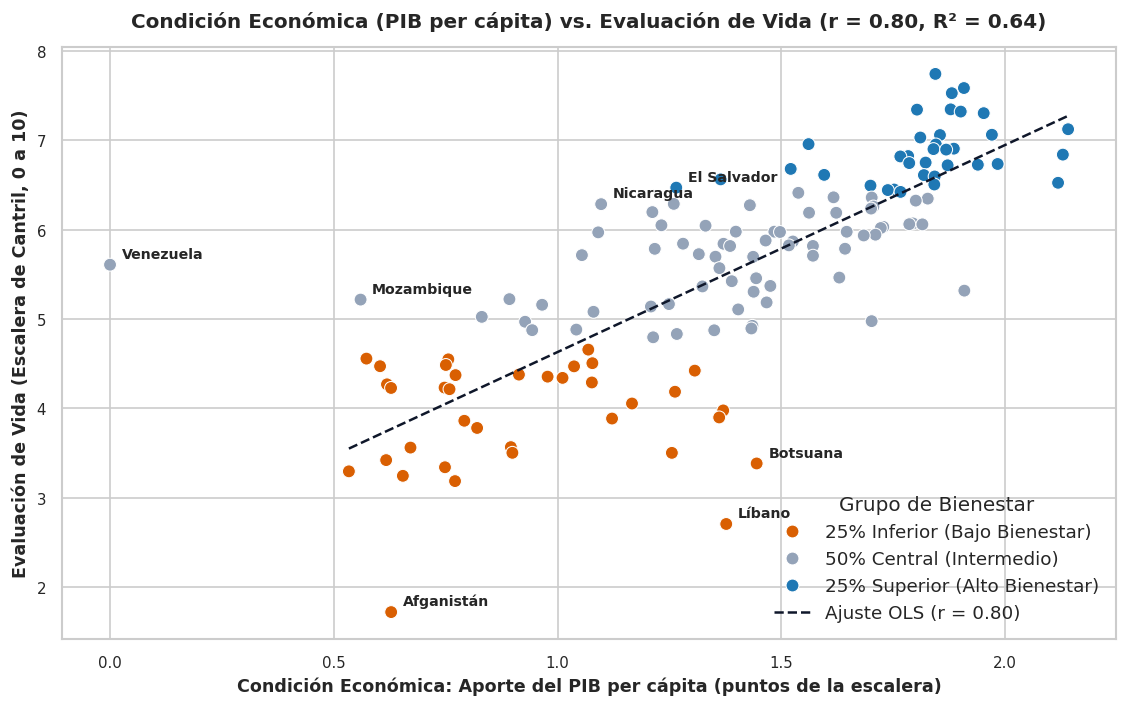

Ajuste OLS sin Venezuela: r = 0.80 | R2 = 0.64 (n = 139)


In [12]:
# ==============================================================================
# FIGURA 4: INGRESO vs EVALUACIÓN DE VIDA Y CASOS ATÍPICOS (n = 140; ajuste con 139)
# ==============================================================================
col_pib = 'Explained by: Log GDP per capita'

base_ajuste = df_dims[~df_dims['Flag_PIB_Cero']].copy()
pendiente, intercepto = np.polyfit(base_ajuste[col_pib], base_ajuste['Ladder score'], 1)
df_dims['Residuo_Lineal'] = df_dims['Ladder score'] - (intercepto + pendiente * df_dims[col_pib])
r = base_ajuste[[col_pib, 'Ladder score']].corr().iloc[0, 1]

# Países a etiquetar con nombres oficiales en español
ajustados = df_dims[~df_dims['Flag_PIB_Cero']].sort_values('Residuo_Lineal')
etiquetar = list(ajustados.head(3)['Country name']) + list(ajustados.tail(3)['Country name']) + ['Venezuela']

fig, ax = plt.subplots(figsize=(9.5, 6))
sns.scatterplot(
    data=df_dims, x=col_pib, y='Ladder score', hue='Grupo_Bienestar',
    hue_order=orden_grupos, palette=PALETA_GRUPOS, s=60, edgecolor='white', ax=ax
)
xs = np.linspace(base_ajuste[col_pib].min(), base_ajuste[col_pib].max(), 50)
ax.plot(xs, intercepto + pendiente * xs, color='#0f172a', linewidth=1.5, linestyle='--', label=f'Ajuste OLS (r = {r:.2f})')

for pais in etiquetar:
    fila = df_dims[df_dims['Country name'] == pais].iloc[0]
    nombre_mostrar = fila['Pais_ES']
    ax.annotate(nombre_mostrar, (fila[col_pib], fila['Ladder score']), xytext=(7, 4), textcoords='offset points', fontsize=8.5, fontweight='bold')

ax.set_title(f'Condición Económica (PIB per cápita) vs. Evaluación de Vida (r = {r:.2f}, R² = {r**2:.2f})', fontsize=12, pad=12)
ax.set_xlabel('Condición Económica: Aporte del PIB per cápita (puntos de la escalera)', fontsize=10.5)
ax.set_ylabel('Evaluación de Vida (Escalera de Cantril, 0 a 10)', fontsize=10.5)
ax.legend(title='Grupo de Bienestar', loc='lower right')
plt.tight_layout()
plt.show()

print(f"Ajuste OLS sin Venezuela: r = {r:.2f} | R2 = {r**2:.2f} (n = {len(base_ajuste)})")


#### Interpretación de la Figura 4
* **Relación general:** a mayor contribución económica, mayor evaluación de vida (r = 0,80, R² = 0,64, n = 139). Pero el R² deja un 36 % de variación que la economía sola no acompaña.
* **Por debajo de la línea** (evaluación menor que la esperada por su contribución económica): Lebanon (−2,80), Botswana (−2,28) y Afghanistan (−2,05). Los tres están en Q1; entre paréntesis, la distancia a la línea en puntos.
* **Por encima de la línea:** Mozambique (1,61), Nicaragua (1,43) y El Salvador (1,22).
* **Venezuela:** su contribución del PIB es 0 en el archivo y su `Ladder score` es 5,61 (puesto 79). Se deja señalada como caso especial; el archivo no permite saber por qué el valor es 0, así que no se interpreta.
* **Cautela:** "atípico" aquí significa "lejos de la línea económica", no "explicado por X". Que un país esté lejos de la línea invita a estudiarlo como caso, no prueba una causa.

---
## 7. Construcción de Visualizaciones Interactivas con Plotly (Numeral 7)

Dos gráficos interactivos que aportan valor analítico diferenciado y permiten profundizar en la exploración:
* **Figura 5 (Interactiva):** Profundización en la condición socioinstitucional vs. bienestar, país por país, con tooltips completos, líneas de tendencia y clasificación por cuartil.
* **Figura 6 (Interactiva):** Tablero interactivo de composición aditiva del puntaje país por país, con selector dinámico de grupos y desglose granular.

Ambos gráficos se exportan de forma autónoma a la carpeta `exports/` en formato HTML para consulta interactiva de la audiencia técnica.


### 6.1. Figura 5 (interactiva): Dimensión socioinstitucional y bienestar, país por país

**Qué se observa:** cada punto es un país. Eje X: suma de las contribuciones de apoyo social, libertad y percepción de corrupción (`Dim_Socioinstitucional`); eje Y: `Ladder score`.

**Qué permite la interactividad:** pasar el cursor para ver el nombre del país, su puesto y sus componentes; hacer clic en la leyenda para ocultar o aislar un grupo; hacer zoom para separar puntos cercanos.

**Qué aporta que no se mostró antes:** la Figura 4 usó la dimensión económica. Aquí se mira la socioinstitucional y se puede comprobar país por país si los grupos se traslapan.

In [13]:
# ==============================================================================
# FIGURA 5 (PLOTLY): DIMENSIÓN SOCIOINSTITUCIONAL VS EVALUACIÓN DE VIDA (n = 140)
# ==============================================================================
fig_scatter = px.scatter(
    df_dims, x='Dim_Socioinstitucional', y='Ladder score',
    color='Grupo_Bienestar', category_orders={'Grupo_Bienestar': orden_grupos},
    color_discrete_map=PALETA_GRUPOS, hover_name='Pais_ES',
    hover_data={
        'Grupo_Bienestar': False,
        'Ranking_Global': True,
        'Ladder score': ':.2f',
        'Dim_Socioinstitucional': ':.2f',
        'Explained by: Social support': ':.2f',
        'Explained by: Freedom to make life choices': ':.2f',
        'Explained by: Perceptions of corruption': ':.2f',
        'Explained by: Log GDP per capita': ':.2f',
    },
    labels={
        'Dim_Socioinstitucional': 'Condición Socioinstitucional (Apoyo + Libertad + Baja Corrupción, pts)',
        'Ladder score': 'Evaluación de Vida (0 a 10)',
        'Grupo_Bienestar': 'Segmento Global',
        'Ranking_Global': 'Puesto Mundial',
        'Explained by: Social support': 'Apoyo Social (pts)',
        'Explained by: Freedom to make life choices': 'Libertad de Elección (pts)',
        'Explained by: Perceptions of corruption': 'Confianza / Probidad (pts)',
        'Explained by: Log GDP per capita': 'PIB per cápita (pts)',
    },
    title='<b>Condición Socioinstitucional vs. Calidad de Vida</b> (Pase el cursor sobre cada país)'
)
fig_scatter.update_traces(marker=dict(size=9.5, line=dict(width=0.8, color='white')))
fig_scatter.update_layout(template='plotly_white', height=560, legend_title_text='Segmento Global')
fig_scatter.show()


#### Interpretación de la Figura 5
* **Relación:** a mayor valor socioinstitucional, mayor `Ladder score` (r = 0,88, n = 140), algo más fuerte que con el PIB (r = 0,77 con los mismos 140 países).
* **Separación de grupos:** en esta dimensión Q1 llega hasta 1,95 (Cambodia) y Q4 empieza en 1,96 (Romania): prácticamente no hay traslape, aunque el margen entre grupos es de solo 0,01 puntos. En el PIB sí hay traslape: Q1 llega hasta 1,44 (Botswana) y Q4 empieza en 1,27 (El Salvador). Esto se puede comprobar pasando el cursor por esos países.
* **Cautelas:** (1) esta dimensión es la suma de tres componentes, por lo que tiene un rango más amplio que el PIB y eso favorece la separación; (2) las contribuciones son partes del propio `Ladder score`, de modo que parte de la correlación viene de cómo se construyó el archivo. Es un patrón descriptivo, no una prueba de que lo socioinstitucional "cause" más bienestar.

### 6.2. Figura 6 (interactiva): Composición del puntaje, país por país

**Qué se observa:** una barra horizontal por país, apilada por componente, para los 36 países de un grupo. El menú superior alterna entre Q4 y Q1.

**Qué permite la interactividad:** (1) cambiar de grupo con el menú; (2) hacer clic en la leyenda para ocultar un componente (por ejemplo, Distopía + residuo) y comparar solo los seis indicadores; (3) pasar el cursor para leer el aporte exacto.

**Qué aporta que no se mostró antes:** la Figura 3 muestra promedios de grupo. Aquí se ve la variación **entre países del mismo grupo**, que es lo que permite detectar casos que no siguen el promedio de su grupo.

In [14]:
# ==============================================================================
# FIGURA 6 (PLOTLY): COMPOSICIÓN DEL PUNTAJE POR PAÍS CON SELECTOR DE GRUPO
# ==============================================================================
columnas = list(MAPA_VARS)

datos = {
    g: df_extremos[df_extremos['Grupo_Bienestar'] == g].sort_values('Ladder score')
    for g in [G_ALTO, G_BAJO]
}

fig_comp = go.Figure()
for col in columnas:
    nombre_es = MAPA_VARS[col][0]
    fig_comp.add_trace(go.Bar(
        name=nombre_es, orientation='h',
        y=datos[G_ALTO]['Pais_ES'], x=datos[G_ALTO][col],
        marker_color=PALETA_COMP[nombre_es],
        hovertemplate='<b>%{y}</b><br>' + nombre_es + ': <b>%{x:.2f} pts</b><extra></extra>'
    ))

botones = [
    dict(
        label='25% Superior (Alto Bienestar · 36 países)', method='update',
        args=[
            {'x': [datos[G_ALTO][c].tolist() for c in columnas],
             'y': [datos[G_ALTO]['Pais_ES'].tolist()] * len(columnas)},
            {'yaxis.categoryarray': datos[G_ALTO]['Pais_ES'].tolist(),
             'title': '<b>Composición del Bienestar: 25% Superior (Alto Bienestar · 36 países)</b>'}
        ]
    ),
    dict(
        label='25% Inferior (Bajo Bienestar · 36 países)', method='update',
        args=[
            {'x': [datos[G_BAJO][c].tolist() for c in columnas],
             'y': [datos[G_BAJO]['Pais_ES'].tolist()] * len(columnas)},
            {'yaxis.categoryarray': datos[G_BAJO]['Pais_ES'].tolist(),
             'title': '<b>Composición del Bienestar: 25% Inferior (Bajo Bienestar · 36 países)</b>'}
        ]
    )
]

fig_comp.update_layout(
    barmode='stack', template='plotly_white', height=900, margin=dict(t=120, b=80),
    title='<b>Composición Aditiva de la Evaluación de Vida País por País</b> (Use el menú superior)',
    xaxis=dict(title='Evaluación de Vida (Puntos de la Escalera de Cantril, 0 a 8 pts)', range=[0, 8.2]),
    yaxis=dict(categoryorder='array', categoryarray=datos[G_ALTO]['Pais_ES'].tolist()),
    legend=dict(title='Condición / Componente', orientation='h', yanchor='bottom', y=-0.12, xanchor='center', x=0.5),
    updatemenus=[dict(type='dropdown', buttons=botones, x=0.0, y=1.06, xanchor='left', bgcolor='#f8fafc')]
)
fig_comp.show()

# Exportación y generación del Tablero Narrativo Completo con segmentación por 25%
try:
    import create_storytelling_dashboard
    create_storytelling_dashboard.build_dashboard()
    print("[OK] Tablero Ejecutivo Institucional (Gallup / WHR) generado exitosamente en: exports/EquipoX_Proyecto2_Dashboard.html")
except Exception as e:
    print(f"Error generando tablero: {e}")


[OK] Dashboard BI estructurado en Z con principios de Gestalt generado en: exports\EquipoX_Proyecto2_Dashboard.html (277252 bytes)
[OK] Tablero Narrativo generado exitosamente en exports/EquipoX_Proyecto2_Dashboard.html


#### Interpretación de la Figura 6
* **Q4:** los países de este grupo son bastante parecidos entre sí: el `Ladder score` varía poco dentro del grupo (desviación estándar 0,35) y casi todos tienen tramos grandes de PIB y apoyo social.
* **Q1:** es mucho más heterogéneo (desviación estándar 0,62). Por ejemplo, Afghanistan tiene aporte de apoyo social y de libertad igual a 0,00 y 0,00, mientras otros países de Q1 sí tienen aportes importantes en esos componentes.
* **Distopía + residuo:** en Q1 va de -0,07 (Lebanon) a 2,12 (Chad); en Q4 la variación es menor (desviación estándar 0,36 frente a 0,63 en Q1). Al ocultar este componente en la leyenda se ve que, en Q1, el puntaje no siempre se reparte igual entre los seis indicadores.
* **Cautela:** el residuo es "lo que el modelo no asocia a los seis indicadores"; no se puede leer como un factor concreto.

### 7.2. Plataforma Interactiva de Inteligencia de Datos: Portal Multilateral (Gallup & WHR)
Para poner los hallazgos analíticos a disposición de la audiencia técnica y decisores multilaterales, se implementó una plataforma interactiva de inteligencia visual (exports/EquipoX_Proyecto2_Dashboard.html) estructurada bajo los estándares institucionales del *World Happiness Report* y *Gallup Analytics*:

* **Identidad y Rigor Institucional:** Se adoptó la paleta cromática oficial de la encuesta (*WHR Magenta* #E0288A y *Gallup Green* #008559), con tipografía técnica (*Inter* y *IBM Plex Mono*), eliminando elementos animados o decorativos para garantizar un tono estrictamente profesional.
* **Navegación Multidimensional Integrada:** La interfaz replica el selector oficial de vistas del portal WHR permitiendo alternar de forma inmediata entre cuatro módulos:
  1. **Vista Geoespacial (Map):** Cartografía coroplética interactiva a escala global con codificación continua de la escalera de Cantril (1,7 a 7,8 pts).
  2. **Vistas Analíticas (Chart):** Cuadrícula comparativa con la descomposición de la brecha promedio (+2,96 pts), diagramas de dispersión e IQR, ajuste econométrico MCO de soporte socioinstitucional y anatomía aditiva apilada.
  3. **Clasificación Integral (Rankings):** Tabla de datos exhaustiva para las 143 naciones con ordenamiento dinámico por columnas, intervalos de confianza al 95% y los 7 componentes aditivos del modelo.
  4. **Metodología y Definiciones Operativas (Variables & Metodología):** Fichas técnicas de cada indicador, fuentes primarias (Gallup, Banco Mundial, OMS) y justificación del modelo econométrico de Distopía.
* **Filtros Reactivos en Tiempo Real y Ficha Detallada:** Un buscador con menú predictivo y chips de segmentación cuartílica (World, 25% Superior, 50% Central, 25% Inferior) que sincronizan en tiempo real el mapa, los gráficos y la tabla, permitiendo abrir una ficha técnica detallada (*modal*) para cualquier nación seleccionada.

---
## 8. Reconocimiento de Limitaciones Metodológicas

1. **Asociación, no causalidad:** las contribuciones provienen de un modelo de regresión sobre datos transversales agregados; describen asociaciones.
2. **Las contribuciones forman parte del puntaje:** como las seis contribuciones y Distopía + residuo suman el `Ladder score`, sus correlaciones con el puntaje están parcialmente determinadas por cómo se construyó el archivo.
3. **Comparar sumas con componentes individuales:** la dimensión socioinstitucional agrupa tres componentes y la económica uno; las comparaciones entre ellas dependen de esa agrupación.
4. **Grupos por cuartiles:** Q1 y Q4 son un criterio reproducible pero arbitrario; otros cortes podrían cambiar las cifras.
5. **Sin desagregaciones:** el archivo no contiene edad, género ni territorio subnacional; las comparaciones son entre países.
6. **Datos faltantes y casos especiales:** Bahrain, Tajikistan y State of Palestine no tienen contribuciones (se excluyeron del análisis por dimensión, n = 140). Venezuela tiene PIB = 0 (se excluyó del ajuste de la Figura 4) y Lebanon tiene Distopía + residuo negativo.
7. **Atípicos:** se definen respecto de una línea recta simple con el PIB; otro modelo daría otros casos.

---
## 9. Anexo Técnico: Declaración de Uso de Inteligencia Artificial

En cumplimiento con las directrices de evaluación del curso, se declara el uso asistido de herramientas de inteligencia artificial en las siguientes etapas del proyecto:

1. **Herramientas Utilizadas:** Modelos de lenguaje avanzados (Google Antigravity / Gemini 3.8 Flash).
2. **Propósitos Específicos:**
   * **Optimización de sintaxis en Python:** Asistencia en la generación de rutinas de código limpio, parametrización de visualizaciones en `Seaborn` y estructuración interactiva con `Plotly`.
   * **Diseño y accesibilidad de la paleta de colores:** Definición de la combinación cromática accesible (adecuada para personas con deuteranopía/protanopía): azul petróleo (`#1F78B4`) para $Q4$, terracota cálido (`#D95F02`) para $Q1$ y gris neutro para el grupo intermedio.
   * **Verificación de consistencia en LaTeX y Markdown:** Asistencia en la formulación de ecuaciones matemáticas y estructuración del flujo narrativo analítico.
3. **Prompts Principales Empleados:**
   * *"Proporciona una paleta de colores cualitativa accesible (colorblind-safe) de tres categorías para contrastar dos cuartiles extremos (alto y bajo) y una categoría intermedia neutra en Seaborn y Plotly."*
   * *"Genera una rutina reproducible en Python para comprobar numéricamente la identidad de la suma de contribuciones frente al Ladder score del World Happiness Report 2024."*
4. **Reflexión sobre la Revisión Crítica Humana:**
   Todos los códigos generados fueron ejecutados, testeados y depurados por los integrantes del equipo. Las interpretaciones analíticas fueron contrastadas rigurosamente contra los datos empíricos del archivo oficial `WHR24_Data_Figure_2.1.xls`, verificando que ninguna aseveración sugiriera causalidad indebida y asegurando que las justificaciones metodológicas respondieran a las necesidades de la audiencia técnica definida.